In [18]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import os

/var/folders/76/2s_xpvh90mb6kmqg7v55sjxr0000gn/T/ipykernel_53080/1243824634.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(simulated_data.values(), labels=simulated_data.keys(), patch_artist=True)


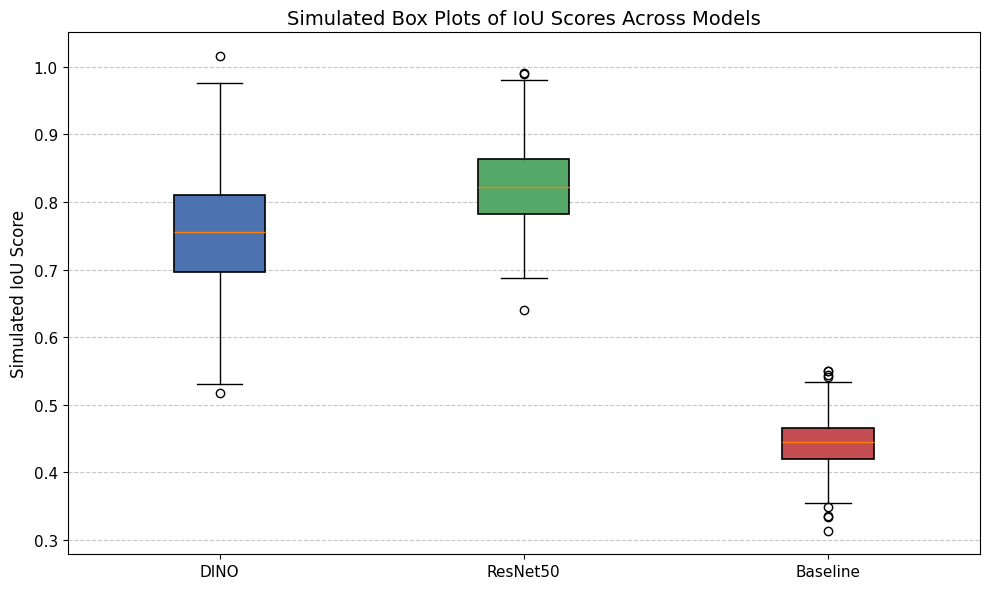

In [20]:

# Paths for each model's fold files
models = {
    "DINO": [f"exports/dino/dino_np/per_image_iou_fold{i}.npy" for i in range(1, 6)],
    "ResNet50": [f"exports/unet/resnet_np/resnet50_per_image_iou_fold{i}.npy" for i in range(1, 6)],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{i}_baseline.npy" for i in range(1, 6)]
}

# For storing simulated samples
simulated_data = {}

# Compute mean, std and simulate data from normal dist
for model_name, file_list in models.items():
    fold_means = []
    fold_stds = []
    for path in file_list:
        ious = np.load(path)
        fold_means.append(np.mean(ious))
        fold_stds.append(np.std(ious, ddof=1))
    
    mean = np.mean(fold_means[:3])  # use only 3 folds as mentioned
    std = np.std(fold_means[:3], ddof=1)
    n = 3
    t_critical = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_critical * (std / np.sqrt(n))
    ci_upper = mean + t_critical * (std / np.sqrt(n))
    
    # Simulate 500 samples from the normal distribution with mean and std
    simulated = np.random.normal(loc=mean, scale=std, size=500)
    simulated_data[model_name] = simulated

# Plotting the boxplot with custom colors for academic report
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red
plt.figure(figsize=(10, 6))
box = plt.boxplot(simulated_data.values(), labels=simulated_data.keys(), patch_artist=True)

# Set custom colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

# Style adjustments
plt.ylabel("Simulated IoU Score", fontsize=12)
plt.title("Simulated Box Plots of IoU Scores Across Models", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

ResNet: Mean = 0.8577, Std = 0.0130, 95% CI = [0.8254, 0.8900]
DINO: Mean = 0.8479, Std = 0.0202, 95% CI = [0.7976, 0.8982]
Baseline: Mean = 0.6249, Std = 0.0501, 95% CI = [0.5004, 0.7494]


/var/folders/76/2s_xpvh90mb6kmqg7v55sjxr0000gn/T/ipykernel_53080/708230366.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(simulated_data, patch_artist=True, labels=labels)


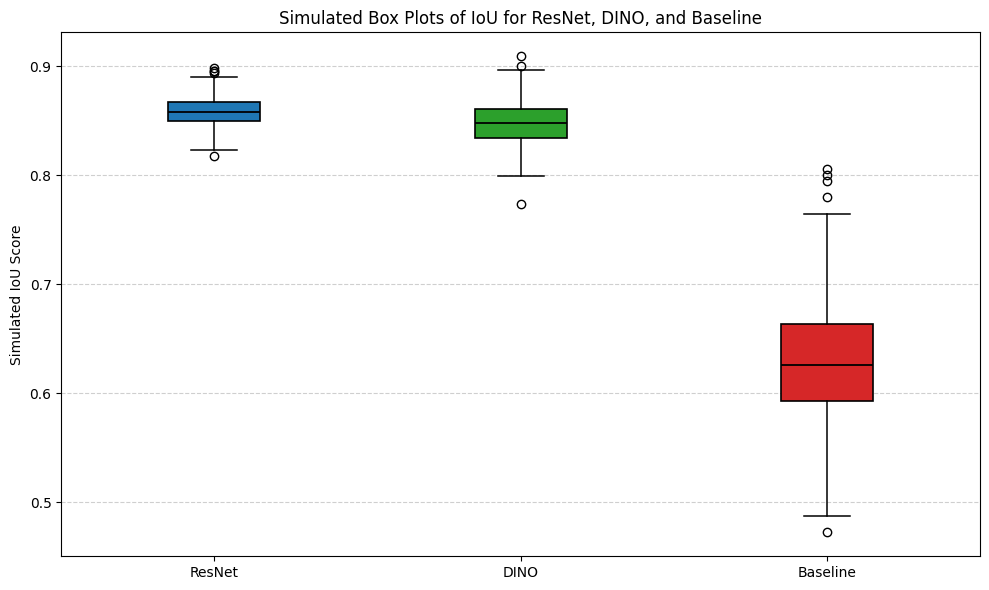

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# === Input: mean and std for each config ===
means = [0.8577, 0.8479, 0.6249]  # ResNet, DINO, Baseline
stds = [0.013, 0.02024, 0.0501]
n = 3  # folds

simulated_data = []
labels = ['ResNet', 'DINO', 'Baseline']
ci_bounds = []

# Simulate data and compute 95% confidence intervals
for i in range(len(means)):
    mean = means[i]
    std = stds[i]
    
    sem = std / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_value * sem
    ci_upper = mean + t_value * sem
    ci_bounds.append((ci_lower, ci_upper))
    
    # Simulate points for visual boxplot
    simulated_points = np.random.normal(loc=mean, scale=std, size=500)
    simulated_data.append(simulated_points)

# Set consistent style
colors = ['#1f77b4', '#2ca02c', '#d62728']  # ResNet, DINO, Baseline

plt.figure(figsize=(10, 6))
box = plt.boxplot(simulated_data, patch_artist=True, labels=labels)

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

for whisker in box['whiskers']:
    whisker.set(color='black', linewidth=1.1)

for cap in box['caps']:
    cap.set(color='black', linewidth=1.1)

for median in box['medians']:
    median.set(color='black', linewidth=1.3)

plt.ylabel('Simulated IoU Score')
plt.title('Simulated Box Plots of IoU for ResNet, DINO, and Baseline')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Print confidence intervals
for label, mean, std, (ci_lower, ci_upper) in zip(labels, means, stds, ci_bounds):
    print(f"{label}: Mean = {mean:.4f}, Std = {std:.4f}, 95% CI = [{ci_lower:.4f}, {ci_upper:.4f}]")

plt.show()

Config 1: Mean = 0.8577, Std = 0.0130, 95% CI = [0.8254, 0.8900]
Config 2: Mean = 0.8576, Std = 0.0140, 95% CI = [0.8228, 0.8924]
Config 3: Mean = 0.8569, Std = 0.0200, 95% CI = [0.8072, 0.9066]
Config 4: Mean = 0.8569, Std = 0.0200, 95% CI = [0.8072, 0.9066]


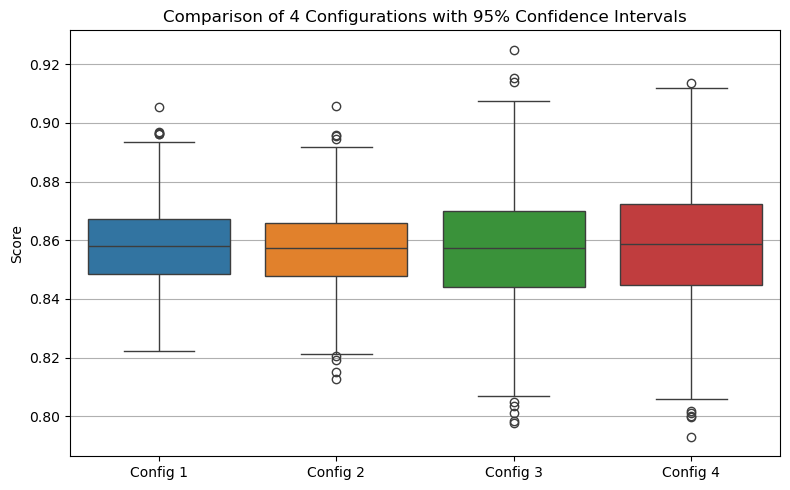

In [5]:
# === Input: mean and std for each config ===
means = [0.8577,0.8576,0.8569,0.8569]
stds  = [0.013,0.014,0.020,0.020]

# Assume n = 3 folds
n = 3

# Prepare data and print 95% CIs
simulated_data = []
labels = []

for i in range(len(means)):
    mean = means[i]
    std = stds[i]
    
    # 95% CI: mean ± t * (std / sqrt(n))
    sem = std / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_value * sem
    ci_upper = mean + t_value * sem
    
    print(f"Config {i+1}: Mean = {mean:.4f}, Std = {std:.4f}, 95% CI = [{ci_lower:.4f}, {ci_upper:.4f}]")
    
    # Simulate n points for boxplot
    simulated_points = np.random.normal(loc=mean, scale=std, size=1000)
    simulated_data.append(simulated_points)
    labels.append(f'Config {i+1}')

# === Plot boxplots ===
plt.figure(figsize=(8, 5))
sns.boxplot(data=simulated_data)
plt.xticks(ticks=np.arange(len(labels)), labels=labels)
plt.ylabel('Score')
plt.title('Comparison of 4 Configurations with 95% Confidence Intervals')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

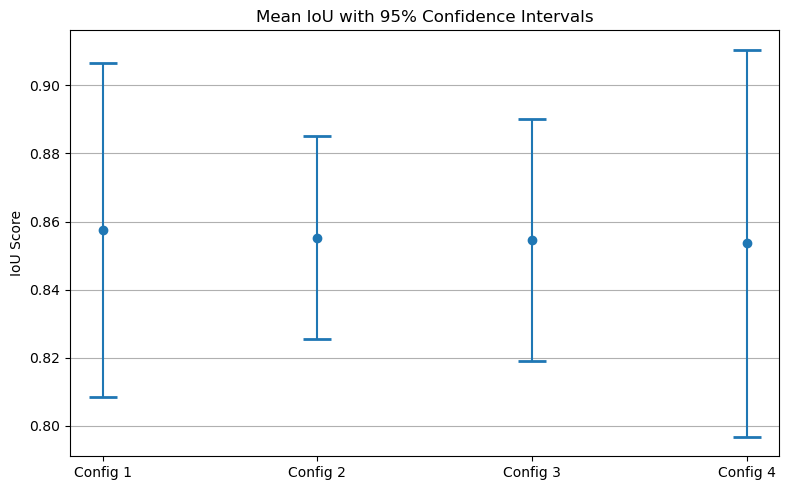

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

means = np.array([0.8575,0.8553,0.8546,0.8536])
stds  = np.array([0.0198,0.0120,0.0143,0.0229])
n = 3

# Calculate 95% CI
sem = stds / np.sqrt(n)
t_value = stats.t.ppf(0.975, df=n-1)
ci_half_width = t_value * sem

# Plot
labels = [f'Config {i+1}' for i in range(len(means))]
x_pos = np.arange(len(means))

plt.figure(figsize=(8,5))
plt.errorbar(x_pos, means, yerr=ci_half_width, fmt='o', capsize=10, capthick=2)
plt.xticks(x_pos, labels)
plt.ylabel('IoU Score')
plt.title('Mean IoU with 95% Confidence Intervals')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

In [11]:
#Friedman test
import numpy as np
from scipy.stats import friedmanchisquare

for fold in range(1, 6):
    iou_dino      = np.load(f"exports/dino/dino_np/per_image_iou_fold{fold}.npy")
    iou_resnet50  = np.load(f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy")
    iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")

# Make sure they have the same length (same images)
assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), "Mismatch in number of images!"

# Run Friedman test
statistic, p_value = friedmanchisquare(iou_dino, iou_resnet50, iou_baseline)

# Print results
print(f"Friedman test statistic: {statistic:.4f}, p-value: {p_value:.4f}")

# Interpret
alpha = 0.05
if p_value < alpha:
    print("→ Significant differences between models (reject H0)")
else:
    print("→ No significant differences between models (fail to reject H0)")

Friedman test statistic: 14.2500, p-value: 0.0008
→ Significant differences between models (reject H0)


In [9]:
import numpy as np
import scikit_posthocs as sp
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize lists to gather all IoUs across all folds
all_iou_dino = []
all_iou_resnet = []
all_iou_baseline = []

# Loop over all 5 folds
for fold in range(1, 6):
    iou_dino      = np.load(f"exports/dino/dino_np/per_image_iou_fold{fold}.npy")
    iou_resnet50  = np.load(f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy")
    iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")

    print(f"Fold {fold}: DINO={len(iou_dino)}, ResNet50={len(iou_resnet50)}, Baseline={len(iou_baseline)}")


    # Ensure consistency
    assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), f"Mismatch in fold {fold}"

    # Extend lists
    all_iou_dino.extend(iou_dino)
    all_iou_resnet.extend(iou_resnet50)
    all_iou_baseline.extend(iou_baseline)

# Stack into shape (num_samples, 3)
data = np.vstack([all_iou_dino, all_iou_resnet, all_iou_baseline]).T

# Run the Nemenyi test
nemenyi_result = sp.posthoc_nemenyi_friedman(data)

# Print result
print("Combined Nemenyi post-hoc test (p-values):")
print(nemenyi_result)


Fold 1: DINO=9, ResNet50=9, Baseline=9
Fold 2: DINO=8, ResNet50=8, Baseline=8
Fold 3: DINO=8, ResNet50=8, Baseline=8
Fold 4: DINO=8, ResNet50=8, Baseline=8
Fold 5: DINO=8, ResNet50=8, Baseline=8
Combined Nemenyi post-hoc test (p-values):
              0             1             2
0  1.000000e+00  1.151930e-01  1.376476e-07
1  1.151930e-01  1.000000e+00  2.712275e-13
2  1.376476e-07  2.712275e-13  1.000000e+00
